# Task 1: Unsupervised Learning & Dimensionality Reduction (PCA)

**Dataset:** `customers.csv`

## Mục tiêu
1.  Chuẩn hóa đặc trưng (Feature Scaling): Áp dụng `StandardScaler()` hoặc `MinMaxScaler()` cho các đặc trưng trước khi thực hiện PCA để đảm bảo việc tính toán phương sai được chính xác.
2. Lựa chọn thành phần (Component Selection): Tính toán tỷ lệ phương sai tích lũy được giải thích (Cumulative Explained Variance Ratio). Chọn số lượng thành phần tối thiểu cần thiết để giữ lại từ 85% đến 95% phương sai của tập dữ liệu gốc.
3. Trực quan hóa kết quả (Visual Output): Tạo biểu đồ phương sai dạng "khuỷu tay" (Elbow plot) hoặc biểu đồ phân tán (scatter plot) 2D/3D để hiển thị các điểm dữ liệu đã được chiếu vào không gian các thành phần chính mới.


**Quy tắc xử lý:** Không dùng `customer_id` vì đây là mã định danh; không dùng `churned` vì đây là nhãn mục tiêu cho bài toán Classification. `registration_date` được chuyển thành `tenure_days`. Các biến số được điền thiếu bằng median và chuẩn hóa; biến phân loại được điền bằng giá trị phổ biến nhất và mã hóa One-Hot.

## 1. Import thư viện

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt




## 2. Đọc dữ liệu

In [14]:
# Đọc file dữ liệu.



from google.colab import files

uploaded = files.upload()



Saving customers.csv to customers (1).csv


In [15]:



df = pd.read_csv("customers.csv")

print("Kích thước dữ liệu:", df.shape)
print("\nTên các cột:")
print(df.columns.tolist())

print("\nThông tin dữ liệu:")
df.info()

print("\n5 dòng dữ liệu đầu tiên:")
display(df.head())


Kích thước dữ liệu: (8000, 20)

Tên các cột:
['customer_id', 'country', 'age', 'gender', 'membership_tier', 'registration_date', 'total_orders', 'total_spend_usd', 'avg_order_value_usd', 'days_since_last_purchase', 'preferred_category', 'preferred_device', 'preferred_payment_method', 'acquisition_channel', 'reviews_given', 'avg_review_score', 'returns_made', 'wishlist_items', 'newsletter_subscribed', 'churned']

Thông tin dữ liệu:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               8000 non-null   object 
 1   country                   8000 non-null   object 
 2   age                       8000 non-null   int64  
 3   gender                    8000 non-null   object 
 4   membership_tier           8000 non-null   object 
 5   registration_date         8000 non-null   object 
 6   total_orders 

,customer_id,country,age,gender,membership_tier,registration_date,total_orders,total_spend_usd,avg_order_value_usd,days_since_last_purchase,preferred_category,preferred_device,preferred_payment_method,acquisition_channel,reviews_given,avg_review_score,returns_made,wishlist_items,newsletter_subscribed,churned
0,C00001,United States,40,Male,Free,2019-01-17,4,286.63,63.78,49,Food & Grocery,Mobile,Debit Card,Social Media,1,4.5,0,12,0,0
1,C00002,United States,20,Female,Free,2026-03-04,11,1245.18,107.32,126,Toys & Games,Mobile,Debit Card,Organic Search,2,2.6,1,1,0,0
2,C00003,United States,43,Female,Gold,2026-02-08,4,195.37,42.74,0,Home & Kitchen,Mobile,PayPal,Referral,0,4.8,0,0,1,0
3,C00004,United States,41,Male,Free,2025-03-19,6,99.45,15.61,6,Electronics,Desktop,PayPal,Organic Search,2,4.2,0,8,1,0
4,C00005,France,37,Other,Platinum,2024-09-10,36,2593.21,79.09,161,Clothing & Apparel,Tablet,Debit Card,Social Media,9,4.0,4,5,1,0


## 3. Kiểm tra dữ liệu trùng và thiếu

In [16]:


df = pd.read_csv("customers.csv")

print("Kích thước dữ liệu:", df.shape)

print("\nKiểu dữ liệu:")
print(df.dtypes)

print("\nSố lượng giá trị thiếu:")
print(df.isnull().sum())

print("\nSố dòng trùng lặp:")
print(df.duplicated().sum())

print("\nThống kê các cột số:")
display(df.describe())


Kích thước dữ liệu: (8000, 20)

Kiểu dữ liệu:
customer_id                  object
country                      object
age                           int64
gender                       object
membership_tier              object
registration_date            object
total_orders                  int64
total_spend_usd             float64
avg_order_value_usd         float64
days_since_last_purchase      int64
preferred_category           object
preferred_device             object
preferred_payment_method     object
acquisition_channel          object
reviews_given                 int64
avg_review_score            float64
returns_made                  int64
wishlist_items                int64
newsletter_subscribed         int64
churned                       int64
dtype: object

Số lượng giá trị thiếu:
customer_id                 0
country                     0
age                         0
gender                      0
membership_tier             0
registration_date           0
total_orders   

,age,total_orders,total_spend_usd,avg_order_value_usd,days_since_last_purchase,reviews_given,avg_review_score,returns_made,wishlist_items,newsletter_subscribed,churned
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,35.616375,16.545250,1558.642350,94.845566,59.583875,3.228750,4.109112,0.849500,4.457125,0.617375,0.089375
std,11.170455,14.681064,2284.094953,78.992885,60.610355,3.942698,0.523992,1.407337,4.854391,0.486058,0.285302
min,18.000000,1.000000,4.890000,5.000000,0.000000,0.000000,1.800000,0.000000,0.000000,0.000000,0.000000
25%,27.000000,5.000000,336.055000,44.690000,16.000000,0.000000,3.800000,0.000000,1.000000,0.000000,0.000000
50%,35.000000,12.000000,845.700000,72.270000,41.000000,2.000000,4.200000,0.000000,3.000000,1.000000,0.000000
75%,43.000000,23.000000,1892.165000,118.560000,84.000000,5.000000,4.500000,1.000000,6.000000,1.000000,0.000000
max,75.000000,79.000000,61282.480000,1051.730000,582.000000,28.000000,5.000000,11.000000,41.000000,1.000000,1.000000


## 4. Feature Selection – Lựa chọn đặc trưng cho PCA
  4.1. Mục đích lựa chọn đặc trưng
Trước khi áp dụng Principal Component Analysis (PCA), nhóm tiến hành lựa chọn các đặc trưng phù hợp từ bộ dữ liệu khách hàng. Mục tiêu là tập trung vào những thuộc tính phản ánh đặc điểm cá nhân và hành vi mua sắm của khách hàng, đồng thời loại bỏ các cột định danh hoặc các biến không phù hợp để đưa trực tiếp vào quá trình phân tích.

Nhóm lựa chọn 10 đặc trưng số để thực hiện PCA. Các đặc trưng này đại diện cho những khía cạnh như nhân khẩu học, mức độ mua sắm, giá trị giao dịch, mức độ tương tác và hành vi sử dụng dịch vụ. Việc lựa chọn này giúp PCA tìm ra các tổ hợp tuyến tính có khả năng tóm tắt thông tin từ những đặc trưng ban đầu trong số chiều thấp hơn.


### 10 đặc trưng nhóm chọn

| Đặc trưng | Ý nghĩa | Lý do lựa chọn |
|---|---|---|
| `age` | Tuổi khách hàng | Phản ánh đặc điểm nhân khẩu học, hỗ trợ xem xét sự khác biệt trong hành vi mua sắm giữa các nhóm tuổi. |
| `total_orders` | Tổng số đơn hàng | Đại diện cho tần suất mua hàng và mức độ hoạt động của khách hàng. |
| `total_spend_usd` | Tổng chi tiêu (USD) | Phản ánh tổng giá trị khách hàng đã chi tiêu, thể hiện quy mô chi tiêu tích lũy. |
| `avg_order_value_usd` | Giá trị đơn hàng trung bình (USD) | Cho biết mức chi tiêu trung bình trên mỗi đơn hàng, bổ sung góc nhìn về quy mô giao dịch bên cạnh tổng chi tiêu. |
| `days_since_last_purchase` | Số ngày kể từ lần mua gần nhất | Phản ánh mức độ gần đây của hoạt động mua hàng; giá trị lớn hơn có thể cho thấy khách hàng đã lâu chưa quay lại mua sắm. |
| `reviews_given` | Số lượt đánh giá | Đại diện cho mức độ tương tác của khách hàng thông qua việc đánh giá sản phẩm hoặc dịch vụ. |
| `avg_review_score` | Điểm đánh giá trung bình | Phản ánh mức điểm khách hàng dành cho các trải nghiệm đã đánh giá. |
| `returns_made` | Số lần trả hàng | Thể hiện một khía cạnh trong hành vi sau mua hàng, có thể liên quan đến trải nghiệm sản phẩm hoặc mức độ phù hợp của đơn hàng. |
| `wishlist_items` | Số sản phẩm trong danh sách yêu thích | Phản ánh hành vi quan tâm đến sản phẩm và có thể cung cấp thông tin bổ sung về sở thích mua sắm. |
| `newsletter_subscribed` | Trạng thái đăng ký nhận bản tin | Thể hiện việc khách hàng có đăng ký nhận bản tin hay không, qua đó phản ánh một hình thức tương tác với kênh truyền thông của doanh nghiệp. |



### Các đặc trưng bị loại khỏi PCA (Excluded Features)

| Đặc trưng | Ý nghĩa | Lý do loại bỏ |
|---|---|---|
| `customer_id` | Mã định danh khách hàng | Là mã định danh dùng để phân biệt khách hàng, không trực tiếp phản ánh đặc điểm hoặc hành vi mua sắm. |
| `country` | Quốc gia của khách hàng | Là dữ liệu phân loại, cần được mã hóa trước khi sử dụng trong PCA. Nhóm tạm thời loại bỏ để tập trung vào các đặc trưng số. |
| `gender` | Giới tính khách hàng | Là dữ liệu phân loại, cần được mã hóa nếu đưa vào PCA. |
| `membership_tier` | Cấp độ thành viên | Là dữ liệu phân loại về cấp độ thành viên, cần được mã hóa phù hợp trước khi sử dụng. |
| `registration_date` | Ngày đăng ký tài khoản | Là dữ liệu ngày tháng, cần được chuyển đổi thành đặc trưng số có ý nghĩa trước khi sử dụng. |
| `preferred_category` | Danh mục sản phẩm ưa thích | Là dữ liệu phân loại, cần được mã hóa trước khi đưa vào PCA. |
| `preferred_device` | Thiết bị ưa thích | Là dữ liệu phân loại, cần được mã hóa nếu sử dụng trong PCA. |
| `preferred_payment_method` | Phương thức thanh toán ưa thích | Là dữ liệu phân loại, cần được mã hóa trước khi sử dụng. |
| `acquisition_channel` | Kênh thu hút khách hàng | Là dữ liệu phân loại, cần được mã hóa nếu muốn đưa vào PCA. |
| `churned` | Trạng thái khách hàng rời bỏ | Được giữ riêng để dự kiến sử dụng làm biến mục tiêu trong bài toán phân loại ở Task 4. |


Bảng phương sai giải thích:


,Principal Component,Explained Variance Ratio,Cumulative Explained Variance
0,PC1,0.2903,0.2903
1,PC2,0.1349,0.4251
2,PC3,0.1028,0.5280
3,PC4,0.1008,0.6287
4,PC5,0.1000,0.7288
5,PC6,0.0986,0.8274
6,PC7,0.0975,0.9249
7,PC8,0.0404,0.9652
8,PC9,0.0235,0.9887
9,PC10,0.0113,1.0000


Số thành phần tối thiểu để giữ ít nhất 85% phương sai: 7
Số thành phần tối thiểu để giữ ít nhất 95% phương sai: 8


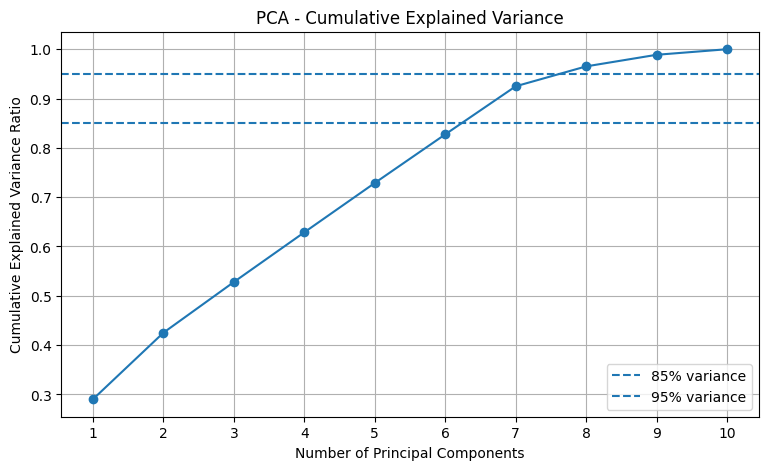

In [17]:



from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 1. Đọc dữ liệu
df = pd.read_csv("customers.csv")

# 2. Chọn các đặc trưng cho PCA
features = [
    "age",
    "total_orders",
    "total_spend_usd",
    "avg_order_value_usd",
    "days_since_last_purchase",
    "reviews_given",
    "avg_review_score",
    "returns_made",
    "wishlist_items",
    "newsletter_subscribed"
]

X = df[features]

# 3. Chuẩn hóa dữ liệu
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. PCA trên toàn bộ đặc trưng
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# 5. Tính phương sai giải thích
explained_variance = pca.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# 6. Hiển thị kết quả
variance_table = pd.DataFrame({
    "Principal Component": [
        f"PC{i+1}" for i in range(len(explained_variance))
    ],
    "Explained Variance Ratio": explained_variance,
    "Cumulative Explained Variance": cumulative_variance
})

print("Bảng phương sai giải thích:")
display(variance_table.round(4))

# 7. Tìm số thành phần tối thiểu để đạt 85% và 95%
n_85 = np.argmax(cumulative_variance >= 0.85) + 1
n_95 = np.argmax(cumulative_variance >= 0.95) + 1

print("Số thành phần tối thiểu để giữ ít nhất 85% phương sai:", n_85)
print("Số thành phần tối thiểu để giữ ít nhất 95% phương sai:", n_95)

# 8. Vẽ biểu đồ phương sai tích lũy
plt.figure(figsize=(9, 5))
plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(y=0.85, linestyle="--", label="85% variance")
plt.axhline(y=0.95, linestyle="--", label="95% variance")

plt.xticks(range(1, len(cumulative_variance) + 1))
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.title("PCA - Cumulative Explained Variance")
plt.grid(True)
plt.legend()
plt.show()


### Kết quả phân tích PCA và lựa chọn số thành phần chính

Sau khi chuẩn hóa 10 đặc trưng bằng phương pháp StandardScaler, nhóm áp dụng Principal Component Analysis (PCA) để xác định các thành phần chính và tỷ lệ phương sai mà chúng giải thích.

Kết quả cho thấy thành phần chính thứ nhất (PC1) giải thích 29,03% tổng phương sai. Khi kết hợp sáu thành phần chính đầu tiên, tỷ lệ phương sai tích lũy đạt 82,74%, chưa đáp ứng ngưỡng tối thiểu 85% theo yêu cầu của đề bài. Khi bổ sung thành phần chính thứ bảy (PC7), tỷ lệ phương sai tích lũy tăng lên 92,49%.

Do đó, nhóm lựa chọn **7 thành phần chính**, giúp giữ lại 92,49% thông tin biến thiên của dữ liệu theo thước đo phương sai, đồng thời giảm số chiều từ 10 đặc trưng ban đầu xuống còn 7 thành phần chính. Lựa chọn này đáp ứng yêu cầu giữ lại từ 85% đến 95% phương sai của đề bài và tạo cơ sở cho các bước phân tích tiếp theo.

## 5. Giảm dữ liệu xuống còn 7 thành phần chính


In [18]:

# Giảm dữ liệu xuống còn 7 thành phần chính
pca_7 = PCA(n_components=7)

X_pca_7 = pca_7.fit_transform(X_scaled)

# Tạo DataFrame cho dữ liệu PCA
pca_columns = [f"PC{i}" for i in range(1, 8)]

df_pca = pd.DataFrame(
    X_pca_7,
    columns=pca_columns,
    index=df.index
)

print("Kích thước dữ liệu ban đầu:", X.shape)
print("Kích thước dữ liệu sau PCA:", df_pca.shape)

print("\n5 dòng đầu của dữ liệu sau PCA:")
display(df_pca.head())

print(
    "\nTổng phương sai giải thích:",
    round(pca_7.explained_variance_ratio_.sum() * 100, 2),
    "%"
)


Kích thước dữ liệu ban đầu: (8000, 10)
Kích thước dữ liệu sau PCA: (8000, 7)

5 dòng đầu của dữ liệu sau PCA:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
0,-1.339517,-0.283761,-0.234749,-1.383924,1.020413,1.092711,-0.719246
1,-0.371033,0.294296,-1.751580,2.425165,1.339023,-1.361128,-0.976470
2,-1.501754,-0.354212,0.764205,-1.030183,-1.669541,-0.253182,0.408849
3,-1.278520,-0.734794,0.832047,-0.847530,0.312784,-0.185581,0.815336
4,2.688528,-0.991777,-0.191592,1.341395,0.034736,0.963078,0.949183



Tổng phương sai giải thích: 92.49 %


### Kết quả giảm chiều dữ liệu bằng PCA

Sau khi chuẩn hóa dữ liệu bằng StandardScaler, nhóm áp dụng Principal Component Analysis (PCA) để giảm số chiều của bộ dữ liệu khách hàng. Ban đầu, dữ liệu đầu vào gồm 8.000 quan sát và 10 đặc trưng số. Dựa trên tỷ lệ phương sai giải thích tích lũy, nhóm lựa chọn 7 thành phần chính, đạt tổng phương sai giải thích 92,49%.

Sau khi áp dụng PCA, bộ dữ liệu được chuyển đổi từ 10 đặc trưng ban đầu thành 7 thành phần chính, trong khi vẫn giữ lại 92,49% phương sai của dữ liệu theo phép biến đổi này. Như vậy, số chiều dữ liệu đã giảm 30%, giúp tạo ra biểu diễn dữ liệu gọn hơn để phục vụ các bước phân tích tiếp theo, đặc biệt là phân cụm khách hàng bằng K-Means.

# Task 2 – Customer Segmentation & Clustering (K-Means)

1. Tìm số cụm K phù hợp


*   Elbow Method: xem tổng bình phương khoảng cách trong cụm (WCSS) giảm như thế nào khi tăng số cụm.
*   Silhouette Score: đánh giá mức độ gắn kết trong cùng cụm và mức độ tách biệt giữa các cụm. Điểm càng gần 1 thường cho thấy cụm càng rõ ràng; điểm gần 0 cho thấy các cụm có thể chồng lấn.






Dữ liệu gốc đã chuẩn hóa: (8000, 10)
Dữ liệu PCA: (8000, 7)
K-Means trên dữ liệu gốc đã chuẩn hóa:


,K,WCSS,Silhouette
0,2,64492.9159,0.2945
1,3,58053.2465,0.1597
2,4,53795.9327,0.1604
3,5,50543.6548,0.1610
4,6,47852.7259,0.1412
5,7,44885.8598,0.1564
6,8,42700.4877,0.1509
7,9,40718.2447,0.1463
8,10,39116.0360,0.1247


K-Means trên dữ liệu PCA:


,K,WCSS,Silhouette
0,2,58485.1538,0.2966
1,3,52043.2641,0.1782
2,4,47853.5250,0.1801
3,5,44432.2882,0.1790
4,6,41333.3799,0.1812
5,7,38982.3905,0.1745
6,8,37087.1468,0.1388
7,9,35187.6511,0.1413
8,10,33631.0828,0.1424


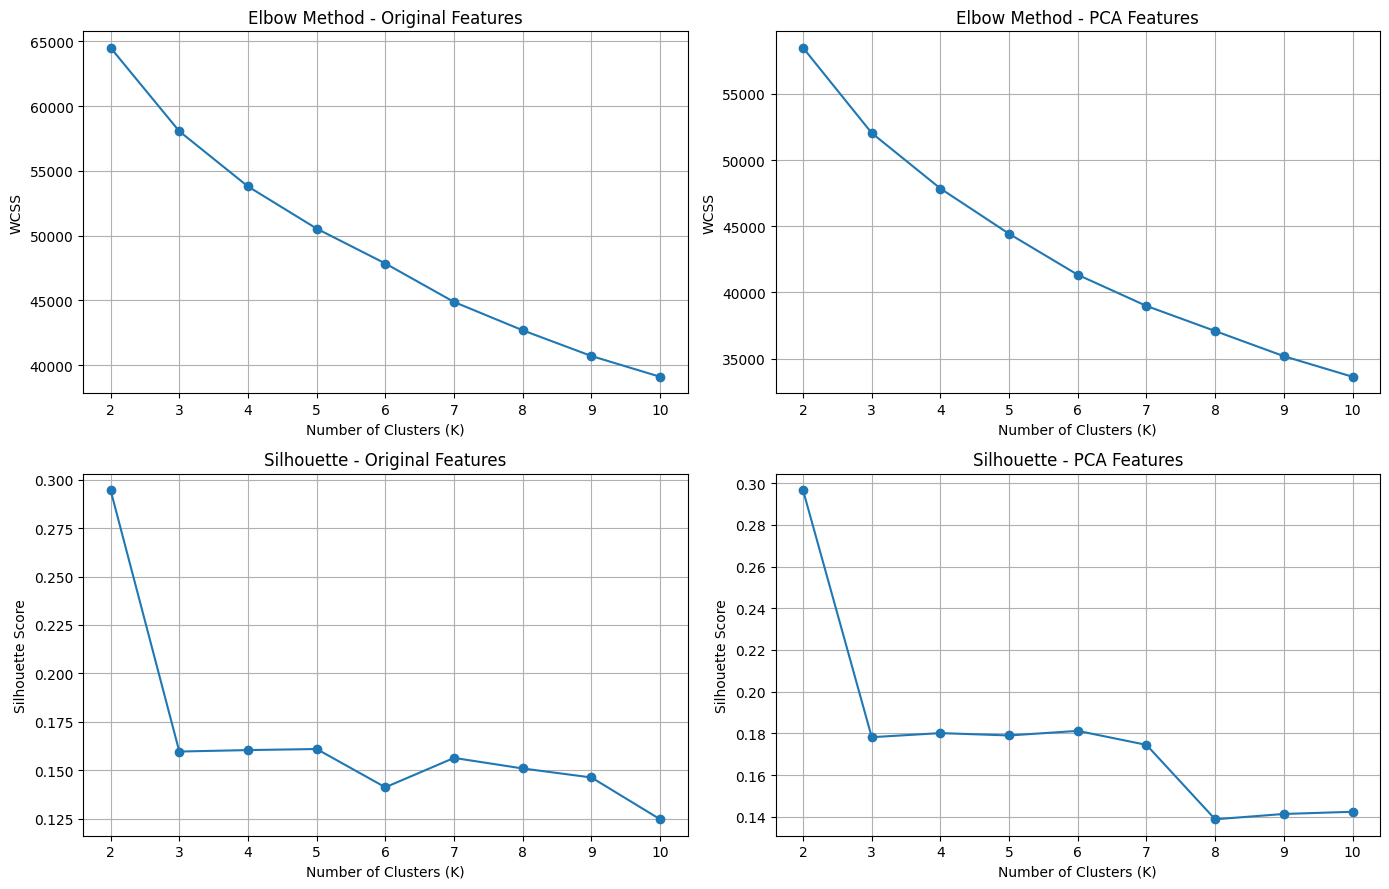

In [19]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd
import matplotlib.pyplot as plt

# Kiểm tra các biến đã tạo ở Task 1
print("Dữ liệu gốc đã chuẩn hóa:", X_scaled.shape)
print("Dữ liệu PCA:", X_pca_7.shape)

# Khảo sát số cụm từ K = 2 đến K = 10
k_values = range(2, 11)

results_original = []
results_pca = []

for k in k_values:
    # K-Means trên dữ liệu gốc đã chuẩn hóa
    km_original = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels_original = km_original.fit_predict(X_scaled)

    results_original.append({
        "K": k,
        "WCSS": km_original.inertia_,
        "Silhouette": silhouette_score(
            X_scaled,
            labels_original,
            sample_size=2000,
            random_state=42
        )
    })

    # K-Means trên dữ liệu đã giảm chiều bằng PCA
    km_pca = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels_pca = km_pca.fit_predict(X_pca_7)

    results_pca.append({
        "K": k,
        "WCSS": km_pca.inertia_,
        "Silhouette": silhouette_score(
            X_pca_7,
            labels_pca,
            sample_size=2000,
            random_state=42
        )
    })

# Chuyển kết quả thành bảng
results_original = pd.DataFrame(results_original)
results_pca = pd.DataFrame(results_pca)

print("K-Means trên dữ liệu gốc đã chuẩn hóa:")
display(results_original.round(4))

print("K-Means trên dữ liệu PCA:")
display(results_pca.round(4))

# Vẽ biểu đồ Elbow và Silhouette
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

axes[0, 0].plot(
    results_original["K"], results_original["WCSS"], marker="o"
)
axes[0, 0].set_title("Elbow Method - Original Features")
axes[0, 0].set_xlabel("Number of Clusters (K)")
axes[0, 0].set_ylabel("WCSS")
axes[0, 0].grid(True)

axes[0, 1].plot(
    results_pca["K"], results_pca["WCSS"], marker="o"
)
axes[0, 1].set_title("Elbow Method - PCA Features")
axes[0, 1].set_xlabel("Number of Clusters (K)")
axes[0, 1].set_ylabel("WCSS")
axes[0, 1].grid(True)

axes[1, 0].plot(
    results_original["K"],
    results_original["Silhouette"],
    marker="o"
)
axes[1, 0].set_title("Silhouette - Original Features")
axes[1, 0].set_xlabel("Number of Clusters (K)")
axes[1, 0].set_ylabel("Silhouette Score")
axes[1, 0].grid(True)

axes[1, 1].plot(
    results_pca["K"],
    results_pca["Silhouette"],
    marker="o"
)
axes[1, 1].set_title("Silhouette - PCA Features")
axes[1, 1].set_xlabel("Number of Clusters (K)")
axes[1, 1].set_ylabel("Silhouette Score")
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()


#1.1 Phân tích kết quả Elbow Method
Biểu đồ Elbow thể hiện WCSS — tổng bình phương khoảng cách giữa các điểm dữ liệu và tâm cụm của chúng. WCSS càng thấp thì dữ liệu càng gần tâm cụm, nhưng giá trị này thường giảm khi tăng số cụm.
- Dữ liệu gốc: WCSS giảm từ khoảng 64.493 khi \(K=2\) xuống khoảng 39.116 khi \(K=10\).
- Dữ liệu PCA: WCSS giảm từ khoảng 58.485 khi \(K=2\) xuống khoảng 33.631 khi \(K=10\).

Trong cả hai biểu đồ, đường cong giảm tương đối đều và không xuất hiện một điểm gấp khúc thật sự rõ ràng. Vì vậy, chỉ dựa vào Elbow Method thì chưa thể xác định chắc chắn một giá trị \(K\) tối ưu.

#1.2 Phân tích Silhouette Score
Silhouette Score giúp đánh giá độ gắn kết trong mỗi cụm và mức độ tách biệt giữa các cụm. Điểm càng cao thường càng tốt.

*   K = 2 có Silhouette Score cao nhất trên cả dữ liệu gốc và dữ liệu PCA.
*   Với dữ liệu gốc, điểm giảm mạnh từ 0,2945 ở \(K=2\) xuống 0,1597 ở \(K=3\).

*   Với dữ liệu PCA, điểm cũng giảm mạnh từ 0,2966 ở \(K=2\) xuống 0,1782 ở \(K=3\).
*   Khi \(K\) tăng từ 3 trở lên, Silhouette Score nhìn chung thấp hơn đáng kể, cho thấy các cụm khó tách biệt hơn theo chỉ số này.






### Xác định số cụm tối ưu cho K-Means

Nhóm sử dụng Elbow Method và Silhouette Score để khảo sát số cụm phù hợp trong khoảng K = 2 đến K = 10. Elbow Method được sử dụng để quan sát sự thay đổi của WCSS khi số cụm tăng, trong khi Silhouette Score đánh giá mức độ gắn kết của các điểm dữ liệu trong cùng cụm và mức độ tách biệt giữa các cụm.

Kết quả cho thấy biểu đồ Elbow của cả dữ liệu gốc đã chuẩn hóa và dữ liệu sau PCA đều không có điểm gấp khúc rõ ràng. Do đó, Elbow Method chưa cung cấp đủ cơ sở để xác định duy nhất số cụm tối ưu.

Theo Silhouette Score, K = 2 đạt giá trị cao nhất ở cả hai phương án: 0,2945 đối với dữ liệu gốc và 0,2966 đối với dữ liệu PCA. Vì vậy, nhóm lựa chọn K = 2 làm phương án phân cụm ban đầu để tiếp tục đánh giá. Tuy nhiên, điểm Silhouette ở mức tương đối thấp cho thấy mức độ phân tách giữa các cụm còn hạn chế. Nhóm sẽ tiếp tục phân tích kích thước và đặc điểm của từng cụm trước khi đưa ra kết luận cuối cùng.

##2. Huấn luyện K-Means với K = 2

In [20]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# K-Means trên dữ liệu gốc đã chuẩn hóa
kmeans_original = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)
labels_original = kmeans_original.fit_predict(X_scaled)

# K-Means trên dữ liệu PCA
kmeans_pca = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)
labels_pca = kmeans_pca.fit_predict(X_pca_7)

# Gắn nhãn vào dữ liệu khách hàng
df_clustered = df.copy()
df_clustered["Cluster_Original"] = labels_original
df_clustered["Cluster_PCA"] = labels_pca

# Kiểm tra số khách hàng trong từng cụm
print("Số khách hàng theo cụm - Dữ liệu gốc:")
display(
    df_clustered["Cluster_Original"]
    .value_counts()
    .sort_index()
    .rename("Number of Customers")
    .to_frame()
)

print("Số khách hàng theo cụm - Dữ liệu PCA:")
display(
    df_clustered["Cluster_PCA"]
    .value_counts()
    .sort_index()
    .rename("Number of Customers")
    .to_frame()
)

# Hiển thị đặc điểm trung bình của các cụm
cluster_features = [
    "age",
    "total_orders",
    "total_spend_usd",
    "avg_order_value_usd",
    "days_since_last_purchase",
    "reviews_given",
    "avg_review_score",
    "returns_made",
    "wishlist_items"
]

print("Đặc điểm trung bình - Cụm trên dữ liệu gốc:")
display(
    df_clustered.groupby("Cluster_Original")[cluster_features]
    .mean()
    .round(2)
)

print("Đặc điểm trung bình - Cụm trên dữ liệu PCA:")
display(
    df_clustered.groupby("Cluster_PCA")[cluster_features]
    .mean()
    .round(2)
)


Số khách hàng theo cụm - Dữ liệu gốc:


,Number of Customers
Cluster_Original,
0,1735
1,6265


Số khách hàng theo cụm - Dữ liệu PCA:


,Number of Customers
Cluster_PCA,
0,6267
1,1733


Đặc điểm trung bình - Cụm trên dữ liệu gốc:


,age,total_orders,total_spend_usd,avg_order_value_usd,days_since_last_purchase,reviews_given,avg_review_score,returns_made,wishlist_items
Cluster_Original,,,,,,,,,
0,35.65,38.40,4042.86,114.54,57.77,8.62,4.13,2.67,4.48
1,35.61,10.49,870.67,89.39,60.09,1.74,4.10,0.35,4.45


Đặc điểm trung bình - Cụm trên dữ liệu PCA:


,age,total_orders,total_spend_usd,avg_order_value_usd,days_since_last_purchase,reviews_given,avg_review_score,returns_made,wishlist_items
Cluster_PCA,,,,,,,,,
0,35.60,10.50,871.35,89.41,60.07,1.74,4.10,0.35,4.45
1,35.67,38.41,4044.09,114.52,57.81,8.62,4.13,2.67,4.48


# 2.1 Phân tích kết quả phân cụm
### A. Số lượng khách hàng theo cụm (Customer Distribution)
| Phương pháp | Cụm 0 | Cụm 1 |
|---|---:|---:|
| K-Means trên dữ liệu gốc | 1.735 (21,69%) | 6.265 (78,31%) |
| K-Means trên dữ liệu PCA | 6.267 (78,34%) | 1.733 (21,66%) |

**Nhận xét:** Cả hai phương pháp đều chia khách hàng thành hai nhóm có quy mô tương tự nhau. Tuy nhiên, nhãn cụm 0 và 1 có thể khác nhau giữa hai phương pháp, vì vậy cần dựa vào đặc điểm trung bình để so sánh bản chất các cụm.



###B. Đặc điểm trung bình của các cụm - Dữ liệu gốc

| Đặc trưng | Cụm 0 | Cụm 1 |
|---|---:|---:|
| Tuổi (`age`) | 35,65 | 35,61 |
| Tổng số đơn hàng (`total_orders`) | 38,40 | 10,49 |
| Tổng chi tiêu USD (`total_spend_usd`) | 4.042,86 | 870,67 |
| Giá trị đơn hàng trung bình USD (`avg_order_value_usd`) | 114,54 | 89,39 |
| Số ngày từ lần mua gần nhất (`days_since_last_purchase`) | 57,77 | 60,09 |
| Số lượt đánh giá (`reviews_given`) | 8,62 | 1,74 |
| Điểm đánh giá trung bình (`avg_review_score`) | 4,13 | 4,10 |
| Số lần trả hàng (`returns_made`) | 2,67 | 0,35 |
| Số sản phẩm yêu thích (`wishlist_items`) | 4,48 | 4,45 |

**Nhận xét:** Cụm 0 có số đơn hàng, tổng chi tiêu, số lượt đánh giá và số lần trả hàng trung bình cao hơn cụm 1. Vì vậy, cụm 0 có thể được mô tả là nhóm khách hàng có mức độ mua hàng cao hơn.


### C.Đặc điểm trung bình của các cụm - Dữ liệu PCA

| Đặc trưng | Cụm 0 | Cụm 1 |
|---|---:|---:|
| Tuổi (`age`) | 35,60 | 35,67 |
| Tổng số đơn hàng (`total_orders`) | 10,50 | 38,41 |
| Tổng chi tiêu USD (`total_spend_usd`) | 871,35 | 4.044,09 |
| Giá trị đơn hàng trung bình USD (`avg_order_value_usd`) | 89,41 | 114,52 |
| Số ngày từ lần mua gần nhất (`days_since_last_purchase`) | 60,07 | 57,81 |
| Số lượt đánh giá (`reviews_given`) | 1,74 | 8,62 |
| Điểm đánh giá trung bình (`avg_review_score`) | 4,10 | 4,13 |
| Số lần trả hàng (`returns_made`) | 0,35 | 2,67 |
| Số sản phẩm yêu thích (`wishlist_items`) | 4,45 | 4,48 |

**Nhận xét:** Cụm 1 có mức độ mua hàng cao hơn, trong khi cụm 0 có mức độ mua hàng thấp hơn. Kết quả này tương đồng với phân cụm trên dữ liệu gốc, dù số thứ tự nhãn cụm bị đảo ngược.




###2.2 . So sánh dữ liệu gốc và dữ liệu PCA
  Kết quả của hai phương pháp khá giống nhau về đặc điểm trung bình của từng nhóm sau khi ghép theo hành vi. Ví dụ, nhóm mua hàng nhiều có tổng chi tiêu khoảng 4.043 USD ở cả hai phương pháp, trong khi nhóm mua hàng ít có tổng chi tiêu khoảng 871 USD.

Điểm đáng chú ý là PCA đã giảm số chiều từ 10 xuống 7 nhưng vẫn tạo ra các cụm có đặc điểm trung bình tương tự phương pháp dùng dữ liệu gốc. Đây là dấu hiệu tích cực cho thấy việc giảm chiều vẫn giữ lại thông tin hữu ích cho phân cụm trong trường hợp này.

Tuy nhiên, để kết luận phương pháp nào tốt hơn, nhóm cần xem thêm Silhouette Score, khả năng diễn giải cụm và mục tiêu ứng dụng thực tế. Nhãn cụm có thể đảo thứ tự giữa hai phương pháp mà không làm thay đổi bản chất phân cụm.

#Kết quả phân cụm khách hàng bằng K-Means

Nhóm áp dụng thuật toán K-Means với K = 2 trên hai bộ dữ liệu: dữ liệu gốc đã chuẩn hóa gồm 10 đặc trưng và dữ liệu sau PCA gồm 7 thành phần chính.

Đối với dữ liệu gốc, thuật toán chia 8.000 khách hàng thành hai cụm, lần lượt gồm 1.735 khách hàng (21,69%) và 6.265 khách hàng (78,31%). Đối với dữ liệu PCA, hai cụm gồm 6.267 khách hàng (78,34%) và 1.733 khách hàng (21,66%). Mặc dù số thứ tự của các nhãn cụm khác nhau, đặc điểm trung bình cho thấy hai phương pháp đều nhận diện được một nhóm có mức độ mua hàng cao và một nhóm có mức độ mua hàng thấp.

Nhóm có mức độ mua hàng cao có trung bình khoảng 38,4 đơn hàng và tổng chi tiêu khoảng 4.043 USD mỗi khách hàng. Trong khi đó, nhóm có mức độ mua hàng thấp có trung bình khoảng 10,5 đơn hàng và tổng chi tiêu khoảng 871 USD mỗi khách hàng. Nhóm mua hàng nhiều cũng có số lượt đánh giá và số lần trả hàng trung bình cao hơn.

So sánh hai phương pháp cho thấy các đặc điểm trung bình của những nhóm tương ứng khá gần nhau. Kết quả này cho thấy PCA giảm số chiều từ 10 xuống 7 trong khi vẫn duy trì được cấu trúc phân nhóm có ý nghĩa theo các đặc trưng đang xét. Tuy nhiên, chất lượng phân cụm vẫn cần được đánh giá kết hợp với Silhouette Score và các tiêu chí ứng dụng thực tế trước khi đưa ra kết luận cuối cùng.

#3. Trực quan hóa cụm trên mặt phẳng 2D

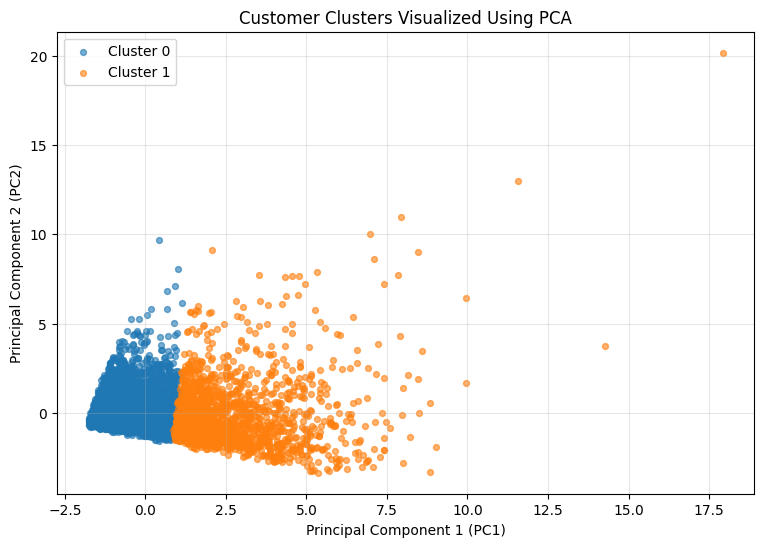

In [21]:

#Trực quan hóa các cụm khách hàng
# Tạo DataFrame cho biểu đồ PCA 2D
plot_df = pd.DataFrame({
    "PC1": X_pca_7[:, 0],
    "PC2": X_pca_7[:, 1],
    "Cluster": df_clustered["Cluster_PCA"].values
})

plt.figure(figsize=(9, 6))

for cluster in sorted(plot_df["Cluster"].unique()):
    subset = plot_df[plot_df["Cluster"] == cluster]
    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Cluster {cluster}",
        alpha=0.6,
        s=18
    )

plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.title("Customer Clusters Visualized Using PCA")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


In [22]:

# Tạo nhãn dễ hiểu dựa trên tổng chi tiêu trung bình
spend_original = df_clustered.groupby(
    "Cluster_Original"
)["total_spend_usd"].mean()

high_original = spend_original.idxmax()

df_clustered["Segment_Original"] = df_clustered[
    "Cluster_Original"
].map({
    high_original: "High_Purchase",
    1 - high_original: "Low_Purchase"
})

spend_pca = df_clustered.groupby(
    "Cluster_PCA"
)["total_spend_usd"].mean()

high_pca = spend_pca.idxmax()

df_clustered["Segment_PCA"] = df_clustered[
    "Cluster_PCA"
].map({
    high_pca: "High_Purchase",
    1 - high_pca: "Low_Purchase"
})

# Lưu dữ liệu kèm nhãn cụm
df_clustered.to_csv("customers_clustered.csv", index=False)

print("Đã lưu file customers_clustered.csv")
print("\nKiểm tra dữ liệu:")
display(
    df_clustered[
        ["customer_id", "Cluster_Original", "Segment_Original",
         "Cluster_PCA", "Segment_PCA"]
    ].head()
)


Đã lưu file customers_clustered.csv

Kiểm tra dữ liệu:


,customer_id,Cluster_Original,Segment_Original,Cluster_PCA,Segment_PCA
0,C00001,1,Low_Purchase,0,Low_Purchase
1,C00002,1,Low_Purchase,0,Low_Purchase
2,C00003,1,Low_Purchase,0,Low_Purchase
3,C00004,1,Low_Purchase,0,Low_Purchase
4,C00005,0,High_Purchase,1,High_Purchase


#Task 3 — Regression: Dự đoán tổng chi tiêu khách hàng
Xây dựng hai mô hình hồi quy theo yêu cầu Stage 2:
- LinearRegression: mô hình hồi quy tuyến tính.
- DecisionTreeRegressor: mô hình cây quyết định hồi quy.

Bước 1. Chọn biến mục tiêu và đặc trưng đầu vào
- Biến mục tiêu (y): total_spend_usd — tổng chi tiêu của khách hàng.
- Biến đầu vào (X): tuổi, số đơn hàng, giá trị đơn hàng trung bình, số ngày từ lần mua gần nhất và các đặc trưng hành vi khác.

Ta không đưa total_spend_usd vào biến đầu vào vì đây chính là giá trị cần dự đoán. Tuy nhiên, total_orders và avg_order_value_usd có thể liên hệ rất chặt với tổng chi tiêu, nên khi đánh giá mô hình, cần lưu ý khả năng dự đoán trở nên dễ dàng do quan hệ sẵn có giữa các biến.

Bước 2. Huấn luyện và so sánh hai mô hình

Kết quả đánh giá mô hình Regression:


,Model,MSE,RMSE,R2
0,Linear Regression,1.573825e+06,1254.5220,0.6875
1,Decision Tree Regressor,2.926704e+05,540.9902,0.9419


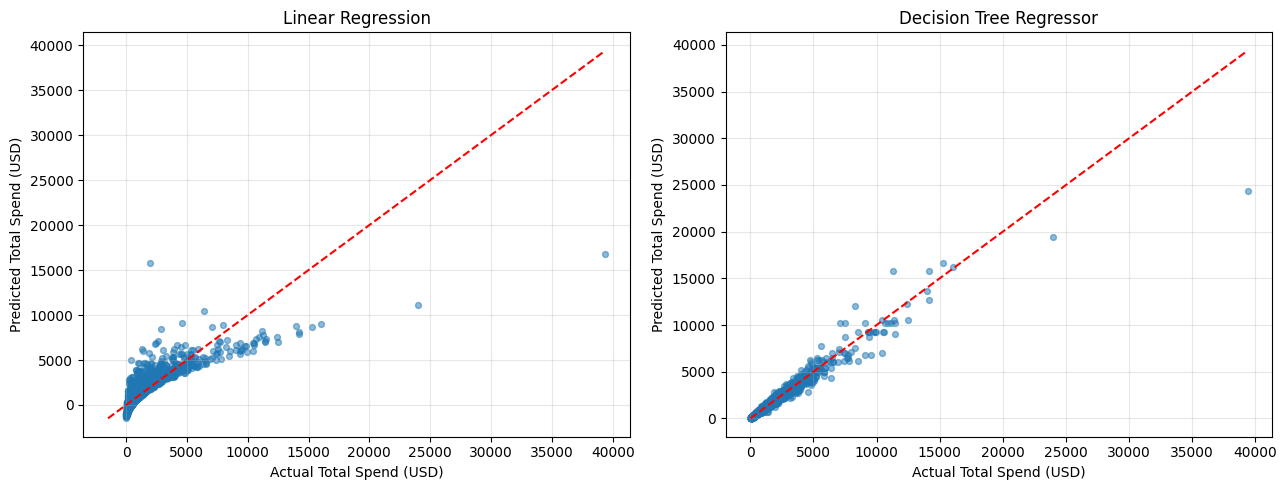

In [23]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Chọn biến đầu vào và biến mục tiêu
regression_features = [
    "age",
    "total_orders",
    "avg_order_value_usd",
    "days_since_last_purchase",
    "reviews_given",
    "avg_review_score",
    "returns_made",
    "wishlist_items",
    "newsletter_subscribed"
]

X_reg = df[regression_features]
y_reg = df["total_spend_usd"]

# 2. Chia dữ liệu huấn luyện và kiểm tra
X_train, X_test, y_train, y_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

# 3. Khởi tạo mô hình
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(
        max_depth=8,
        random_state=42
    )
}

results_regression = []
predictions = {}

# 4. Huấn luyện và đánh giá
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    results_regression.append({
        "Model": name,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

    predictions[name] = y_pred

regression_results = pd.DataFrame(results_regression)

print("Kết quả đánh giá mô hình Regression:")
display(regression_results.round(4))

# 5. Vẽ biểu đồ giá trị thực tế và dự đoán
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.5, s=18)

    # Đường dự đoán hoàn hảo
    lower = min(y_test.min(), y_pred.min())
    upper = max(y_test.max(), y_pred.max())
    ax.plot([lower, upper], [lower, upper], "r--")

    ax.set_title(name)
    ax.set_xlabel("Actual Total Spend (USD)")
    ax.set_ylabel("Predicted Total Spend (USD)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



### Bảng so sánh kết quả các mô hình Regression

| Chỉ số | Linear Regression | Decision Tree Regressor | Mô hình tốt hơn |
|---|---:|---:|---|
| MSE | 1.573.825 | 292.670,4 | Decision Tree |
| RMSE | 1.254,5220 USD | 540,9902 USD | Decision Tree |
| R² | 0,6875 | 0,9419 | Decision Tree |


*  MSE (Mean Squared Error): sai số bình phương trung bình. Giá trị càng thấp thì dự đoán càng tốt.
*  RMSE (Root Mean Squared Error): sai số dự đoán điển hình theo thang đo USD. Linear Regression có RMSE khoảng 1.254,52 USD, trong khi Decision Tree có RMSE khoảng 540,99 USD.
* R² (Coefficient of Determination): đo mức độ mô hình giải thích sự biến thiên của tổng chi tiêu. Linear Regression đạt 0,6875; Decision Tree đạt 0,9419.

**Nhận xét:**

Decision Tree Regressor cho kết quả tốt hơn Linear Regression trên tập kiểm tra. Mô hình có MSE và RMSE thấp hơn, đồng thời đạt R² cao hơn. Cụ thể, RMSE giảm từ 1.254,5220 USD xuống 540,9902 USD, trong khi R² tăng từ 0,6875 lên 0,9419. Vì vậy, nhóm lựa chọn Decision Tree Regressor là mô hình tốt hơn trong hai mô hình được đánh giá cho bài toán dự đoán tổng chi tiêu khách hàng.




### Nhận xét biểu đồ Actual vs Predicted

**1. Biểu đồ Linear Regression**

Quan sát biểu đồ Linear Regression, các điểm dữ liệu phân tán khá xa đường chéo đỏ, đặc biệt ở những khách hàng có tổng chi tiêu cao. Một số điểm có giá trị dự đoán chênh lệch đáng kể so với giá trị thực tế. Điều này cho thấy mô hình Linear Regression chưa dự đoán tốt một số trường hợp trong tập kiểm tra.

**2. Biểu đồ Decision Tree Regressor**

Quan sát biểu đồ Decision Tree Regressor, các điểm dữ liệu nhìn chung nằm gần đường chéo đỏ hơn so với biểu đồ Linear Regression. Tuy nhiên, vẫn có một số điểm ở vùng tổng chi tiêu cao nằm cách xa đường chéo. Điều này cho thấy mô hình cây quyết định dự đoán sát giá trị thực tế hơn trong phần lớn các trường hợp, nhưng vẫn còn sai số ở một số khách hàng.

**3. So sánh hai biểu đồ**

So sánh hai biểu đồ cho thấy Decision Tree Regressor có kết quả dự đoán tốt hơn Linear Regression. Nhận xét này phù hợp với bảng đánh giá mô hình: Decision Tree Regressor có RMSE thấp hơn (540,9902 USD so với 1.254,5220 USD) và R² cao hơn (0,9419 so với 0,6875). Vì vậy, trong hai mô hình được thử nghiệm, Decision Tree Regressor là mô hình phù hợp hơn để dự đoán tổng chi tiêu khách hàng trên tập kiểm tra.


### KỂT LUẬN

Nhóm xây dựng và so sánh hai mô hình hồi quy là Linear Regression và Decision Tree Regressor để dự đoán tổng chi tiêu của khách hàng (`total_spend_usd`). Dữ liệu được chia thành tập huấn luyện và tập kiểm tra theo tỷ lệ 80:20, sử dụng `random_state = 42` để đảm bảo khả năng tái lập kết quả.

Kết quả đánh giá cho thấy Linear Regression đạt MSE khoảng 1.573.825, RMSE khoảng 1.254,52 USD và R² bằng 0,6875. Trong khi đó, Decision Tree Regressor đạt MSE khoảng 292.670,4, RMSE khoảng 540,99 USD và R² bằng 0,9419.

So sánh các chỉ số cho thấy Decision Tree Regressor có sai số dự đoán thấp hơn và khả năng giải thích sự biến thiên của biến mục tiêu cao hơn trên tập kiểm tra. Biểu đồ Actual vs Predicted cũng cho thấy dự đoán của mô hình cây quyết định nhìn chung gần đường chéo biểu thị dự đoán lý tưởng hơn.

Vì vậy, trong hai mô hình được thử nghiệm, nhóm lựa chọn Decision Tree Regressor là mô hình có kết quả tốt hơn cho bài toán dự đoán tổng chi tiêu khách hàng. Kết luận này dựa trên tập kiểm tra hiện tại; nhóm cần tiếp tục kiểm tra khả năng tổng quát hóa và ảnh hưởng của các đặc trưng đầu vào trước khi triển khai thực tế.